# Lab 5 - Statistics

In this notebook I load the classified CSV file and check the results of the pipeline.

## What This Notebook Does

- Loads `classified_packets.csv`.
- Shows how many events were classified.
- Counts events by type, MITRE tactic, and MITRE technique.
- Creates simple charts from the output.

In [1]:
%pip install -q pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "classified_packets.csv"

df = pd.read_csv(CSV_PATH)
df.head()

,event_id,timestamp,user,host,source_ip,event_type,mitre_tactic,mitre_technique,classification_reason
0,1c6b5fe0-8cc4-419c-a4bc-a358dfbc0eca,2026-05-31T14:04:00.067609+00:00,bob,LAPTOP-7,10.0.0.15,user_login,TA0006,T1110,Possible brute force
1,d4c9a61f-92cf-4e5a-b270-42f3dabc6a57,2026-05-31T14:04:00.390316+00:00,bob,WIN-02,192.168.1.50,user_login,TA0006,T1110,Possible brute force
2,1098fda5-504a-4788-a17b-342f4f2dec6b,2026-05-31T14:04:00.591248+00:00,daniel,WIN-02,192.168.1.50,user_login,TA0001,T1078,Valid account login
3,def09e4f-6808-413d-8dce-6b2c0198e365,2026-05-31T14:04:00.791892+00:00,daniel,WIN-02,10.0.0.25,user_login,TA0001,T1078,Valid account login
4,38a3278c-e5d5-4ae1-944e-5c7066fe1e3c,2026-05-31T14:04:00.992720+00:00,alice,WIN-02,192.168.1.50,user_login,TA0001,T1078,Valid account login


In [3]:
print(f"Total classified events: {len(df)}")
print("\nEvent types:")
print(df["event_type"].value_counts())
print("\nMITRE tactics:")
print(df["mitre_tactic"].value_counts())
print("\nMITRE techniques:")
print(df["mitre_technique"].value_counts())

Total classified events: 30

Event types:
event_type
user_login       21
process_start     9
Name: count, dtype: int64

MITRE tactics:
mitre_tactic
TA0001    11
TA0006    10
TA0002     9
Name: count, dtype: int64

MITRE techniques:
mitre_technique
T1078        11
T1110        10
T1059         4
T1059.003     3
T1059.001     2
Name: count, dtype: int64


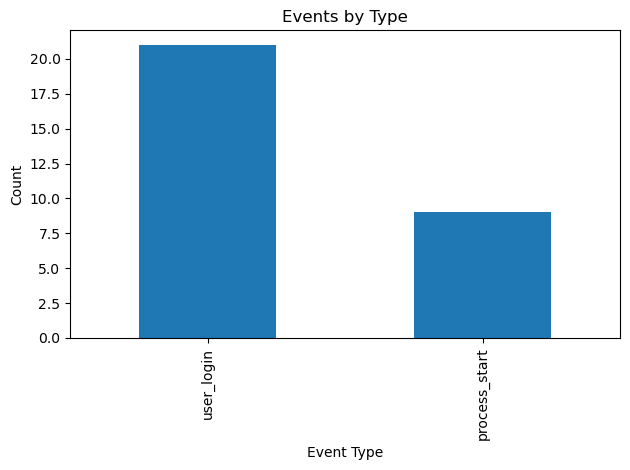

In [4]:
df["event_type"].value_counts().plot(kind="bar", title="Events by Type")
plt.xlabel("Event Type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

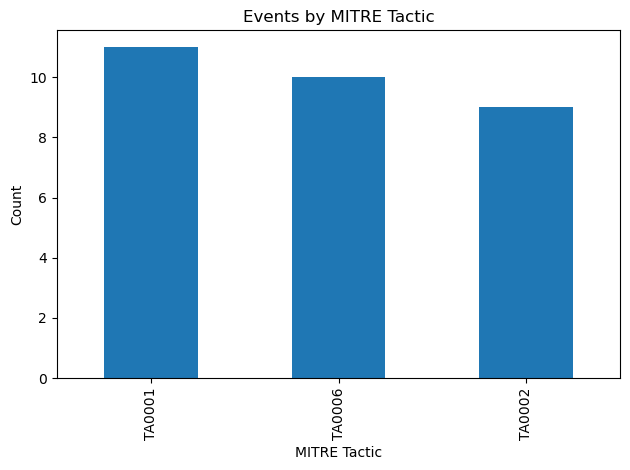

In [5]:
df["mitre_tactic"].value_counts().plot(kind="bar", title="Events by MITRE Tactic")
plt.xlabel("MITRE Tactic")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

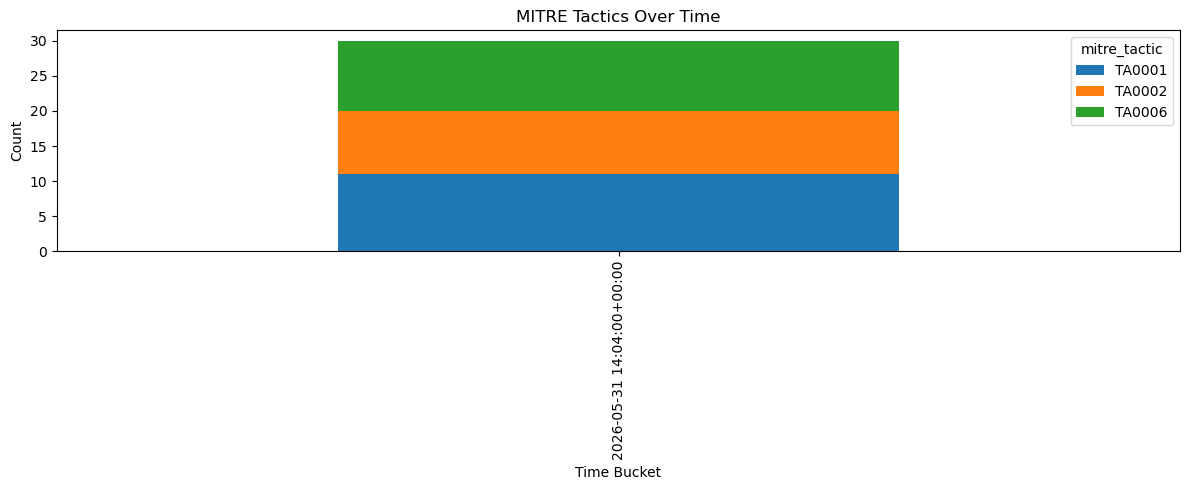

In [6]:
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["time_bucket"] = df["timestamp"].dt.floor("1min")

timeline = df.groupby(["time_bucket", "mitre_tactic"]).size().unstack(fill_value=0)
timeline.plot(kind="bar", stacked=True, figsize=(12, 5), title="MITRE Tactics Over Time")
plt.xlabel("Time Bucket")
plt.ylabel("Count")
plt.tight_layout()
plt.show()